In [1]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)

In [2]:
df=pd.read_csv("../data/fake_job_postings.csv")

In [3]:
df.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [4]:
df.shape

(17880, 18)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   job_id               17880 non-null  int64
 1   title                17880 non-null  str  
 2   location             17534 non-null  str  
 3   department           6333 non-null   str  
 4   salary_range         2868 non-null   str  
 5   company_profile      14572 non-null  str  
 6   description          17879 non-null  str  
 7   requirements         15184 non-null  str  
 8   benefits             10668 non-null  str  
 9   telecommuting        17880 non-null  int64
 10  has_company_logo     17880 non-null  int64
 11  has_questions        17880 non-null  int64
 12  employment_type      14409 non-null  str  
 13  required_experience  10830 non-null  str  
 14  required_education   9775 non-null   str  
 15  industry             12977 non-null  str  
 16  function             11425 non-nu

In [6]:
df.isnull().sum()

job_id                     0
title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                1
requirements            2696
benefits                7212
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function                6455
fraudulent                 0
dtype: int64

In [7]:
(df.isnull().mean() * 100).round(1).sort_values(ascending=False)

salary_range           84.0
department             64.6
required_education     45.3
benefits               40.3
required_experience    39.4
function               36.1
industry               27.4
employment_type        19.4
company_profile        18.5
requirements           15.1
location                1.9
job_id                  0.0
title                   0.0
description             0.0
telecommuting           0.0
has_questions           0.0
has_company_logo        0.0
fraudulent              0.0
dtype: float64

In [8]:
df["fraudulent"].value_counts()

fraudulent
0    17014
1      866
Name: count, dtype: int64

In [9]:
df["fraudulent"].value_counts(normalize=True) * 100

fraudulent
0    95.1566
1     4.8434
Name: proportion, dtype: float64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: C:\Users\uutka\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [12]:
#EDA
import matplotlib.pyplot as plt
import seaborn as sns

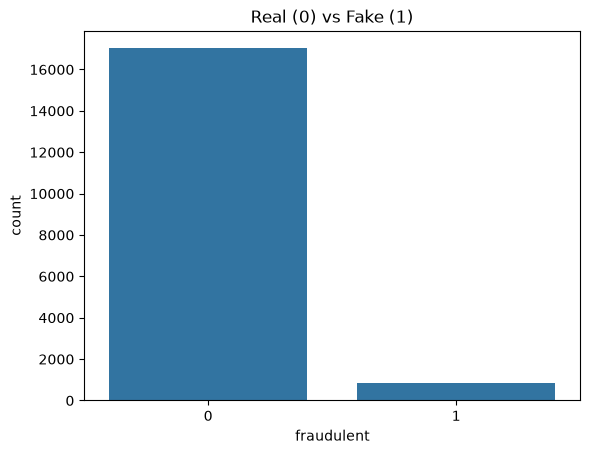

In [13]:
#Target ka graph

sns.countplot(x="fraudulent", data=df)
plt.title("Real (0) vs Fake (1)")
plt.show()

In [14]:
#Kya missing hona fraud ka signal hai?

cols = ["salary_range", "department", "company_profile", "requirements",
        "benefits", "employment_type", "required_experience",
        "required_education", "industry", "function"]

for c in cols:
    rate = df.groupby(df[c].isnull())["fraudulent"].mean() * 100
    print(c)
    print("  value hai:", round(rate.get(False, 0), 1), "% fake")
    print("  value missing:", round(rate.get(True, 0), 1), "% fake")

salary_range
  value hai: 7.8 % fake
  value missing: 4.3 % fake
department
  value hai: 5.3 % fake
  value missing: 4.6 % fake
company_profile
  value hai: 1.9 % fake
  value missing: 17.7 % fake
requirements
  value hai: 4.7 % fake
  value missing: 5.7 % fake
benefits
  value hai: 4.7 % fake
  value missing: 5.0 % fake
employment_type
  value hai: 4.3 % fake
  value missing: 6.9 % fake
required_experience
  value hai: 4.0 % fake
  value missing: 6.2 % fake
required_education
  value hai: 4.2 % fake
  value missing: 5.6 % fake
industry
  value hai: 4.6 % fake
  value missing: 5.6 % fake
function
  value hai: 4.6 % fake
  value missing: 5.2 % fake


In [15]:
#Dekhna ki logo nahi hone par fake ka chance kitna badhta hai.

for c in ["has_company_logo", "has_questions", "telecommuting"]:
    print(df.groupby(c)["fraudulent"].mean() * 100)
    print()


has_company_logo
0    15.928962
1     1.990155
Name: fraudulent, dtype: float64

has_questions
0    6.778169
1    2.843494
Name: fraudulent, dtype: float64

telecommuting
0    4.686496
1    8.344198
Name: fraudulent, dtype: float64



In [16]:
#count batata hai kitni jobs hain, mean batata hai unme fake ka ratio.

df.groupby("employment_type")["fraudulent"].agg(["count", "mean"])

,count,mean
employment_type,,
Contract,1524,0.028871
Full-time,11620,0.042169
Other,227,0.066079
Part-time,797,0.092848
Temporary,241,0.008299


In [17]:
#Description ki length

df["desc_length"] = df["description"].fillna("").str.len()
df.groupby("fraudulent")["desc_length"].describe()

,count,mean,std,min,25%,50%,75%,max
fraudulent,,,,,,,,
0,17014.0,1221.219701,889.139777,6.0,616.0,1027.0,1589.0,14907.0
1,866.0,1154.834873,998.525242,0.0,462.5,844.5,1541.0,8578.0


In [18]:
#Cleaning + Feature Engineering

In [19]:
#Removing Duplicates

print("Pehle:", df.shape)
print("Duplicates:", df.drop(columns="job_id").duplicated().sum())

df = df.drop_duplicates(subset=df.columns.drop("job_id")).reset_index(drop=True)
print("Baad me:", df.shape)

Pehle: (17880, 19)
Duplicates: 281
Baad me: (17599, 19)


In [20]:
df["has_company_profile"] = df["company_profile"].notnull().astype(int)
df["has_salary"] = df["salary_range"].notnull().astype(int)
df["has_employment_type"] = df["employment_type"].notnull().astype(int)

info_cols = ["salary_range", "department", "company_profile", "requirements",
             "benefits", "employment_type", "required_experience",
             "required_education", "industry", "function"]
df["filled_fields"] = df[info_cols].notnull().sum(axis=1)

In [21]:
#Text me missing ko khali string se bharte hain, kyunki model ko text chahiye, NaN nahi.

text_cols = ["title", "company_profile", "description", "requirements", "benefits"]
for c in text_cols:
    df[c] = df[c].fillna("")

In [22]:
#caps_ratio ka matlab description me kitne % letters capital hain. 
#Scam postings aksar “URGENT!!! EARN MONEY” jaisi cheezein likhte hain.

df["title_length"] = df["title"].str.len()
df["desc_length"] = df["description"].str.len()
df["profile_length"] = df["company_profile"].str.len()
df["req_length"] = df["requirements"].str.len()
df["exclaim_count"] = df["description"].str.count("!")
df["caps_ratio"] = df["description"].apply(
    lambda s: sum(ch.isupper() for ch in s) / (len(s) + 1)
)

In [23]:
#Combined text + suspicious words
df["text"] = (df["title"] + " " + df["company_profile"] + " " +
              df["description"] + " " + df["requirements"] + " " +
              df["benefits"]).str.lower()

suspicious = ["earn", "income", "money", "cash", "urgent", "immediately",
              "no experience", "work from home", "investment", "fee", "weekly pay"]

df["suspicious_count"] = df["text"].apply(
    lambda t: sum(t.count(w) for w in suspicious)
)
df["has_email_or_url"] = df["text"].str.contains("#email_|#url_", regex=True).astype(int)



In [24]:
#Country nikalo
df["country"] = df["location"].fillna("unknown").str.split(",").str[0].str.strip()
df["country"].value_counts().head(10)


country
US         10460
GB          2329
GR           938
CA           450
DE           382
unknown      341
NZ           330
IN           273
AU           213
PH           132
Name: count, dtype: int64

In [25]:
#Naye features kaam ke hain ya nahi, ye check karo

new_features = ["has_company_profile", "has_salary", "has_employment_type",
                "has_email_or_url"]
for c in new_features:
    print(df.groupby(c)["fraudulent"].mean() * 100)
    print()

num_cols = ["filled_fields", "title_length", "desc_length", "profile_length",
            "req_length", "exclaim_count", "caps_ratio", "suspicious_count"]
df.groupby("fraudulent")[num_cols].mean().round(2).T

has_company_profile
0    17.672151
1     1.927778
Name: fraudulent, dtype: float64

has_salary
0    4.298673
1    7.817474
Name: fraudulent, dtype: float64

has_employment_type
0    6.884481
1    4.375132
Name: fraudulent, dtype: float64

has_email_or_url
0    4.150408
1    6.136328
Name: fraudulent, dtype: float64



fraudulent,0,1
filled_fields,6.13,5.38
title_length,28.29,30.57
desc_length,1220.23,1158.08
profile_length,639.38,232.01
req_length,598.69,448.13
exclaim_count,0.31,0.21
caps_ratio,0.03,0.04
suspicious_count,1.17,1.60


In [26]:
top = df["country"].value_counts().head(10).index
df[df["country"].isin(top)].groupby("country")["fraudulent"].agg(["count", "mean"]).sort_values("mean", ascending=False)

,count,mean
country,,
AU,213,0.183099
US,10460,0.068929
unknown,341,0.055718
CA,450,0.026667
IN,273,0.014652
GB,2329,0.009875
PH,132,0.007576
DE,382,0.000000
GR,938,0.000000


In [27]:
df["fraudulent"].value_counts()

fraudulent
0    16743
1      856
Name: count, dtype: int64

In [28]:
#Columns ke group banao

num_cols = ["filled_fields", "title_length", "desc_length", "profile_length",
            "req_length", "exclaim_count", "caps_ratio", "suspicious_count"]

bin_cols = ["telecommuting", "has_company_logo", "has_questions",
            "has_company_profile", "has_salary", "has_employment_type",
            "has_email_or_url"]

cat_cols = ["employment_type", "required_experience", "required_education", "country"]

X = df[num_cols + bin_cols + cat_cols + ["text"]]
y = df["fraudulent"]

In [29]:
#Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(14079, 20) (3520, 20)
0.0486540237232758 0.04857954545454545


In [30]:
#Preprocessing setup

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20)),
])

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("bin", "passthrough", bin_cols),
    ("cat", cat_pipe, cat_cols),
    ("tfidf", TfidfVectorizer(max_features=5000, stop_words="english",
                              ngram_range=(1, 2), min_df=5), "text"),
])

In [31]:
#Ye “bewakoof model” hai jo har job ko real bol deta hai. Accuracy lagbhag 95% aayegi, par recall 0 hoga. Yahi dikhata hai ki accuracy yahan bekaar metric hai, aur ye README me likhne layak point hai.


from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
pred = dummy.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred))
print("Recall (fake pakadna):", recall_score(y_test, pred))

Accuracy: 0.9514204545454545
Recall (fake pakadna): 0.0


In [32]:
#Logistic 

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

lr = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

lr.fit(X_train, y_train)

pred = lr.predict(X_test)
proba = lr.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred))
print("ROC-AUC:", roc_auc_score(y_test, proba))
print(confusion_matrix(y_test, pred))

              precision    recall  f1-score   support

           0       1.00      0.96      0.98      3349
           1       0.53      0.92      0.68       171

    accuracy                           0.96      3520
   macro avg       0.76      0.94      0.83      3520
weighted avg       0.97      0.96      0.96      3520

ROC-AUC: 0.9881783686847256
[[3212  137]
 [  14  157]]


In [33]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: C:\Users\uutka\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [34]:
import time
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.preprocessing import MinMaxScaler
from xgboost import XGBClassifier

In [35]:
#Preprocessor ko function bana do

def make_prep(scaler):
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20)),
    ])
    return ColumnTransformer([
        ("num", scaler, num_cols),
        ("bin", "passthrough", bin_cols),
        ("cat", cat_pipe, cat_cols),
        ("tfidf", TfidfVectorizer(max_features=5000, stop_words="english",
                                  ngram_range=(1, 2), min_df=5), "text"),
    ])

In [36]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
print("Imbalance ratio:", round(spw, 1))

models = {
    "Logistic Regression": Pipeline([
        ("prep", make_prep(StandardScaler())),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))]),

    "Linear SVM": Pipeline([
        ("prep", make_prep(StandardScaler())),
        ("model", LinearSVC(class_weight="balanced"))]),

    "Naive Bayes": Pipeline([
        ("prep", make_prep(MinMaxScaler())),
        ("model", ComplementNB())]),

    "Random Forest": Pipeline([
        ("prep", make_prep(StandardScaler())),
        ("model", RandomForestClassifier(n_estimators=200,
                  class_weight="balanced_subsample", n_jobs=-1, random_state=42))]),

    "XGBoost": Pipeline([
        ("prep", make_prep(StandardScaler())),
        ("model", XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6,
                  scale_pos_weight=spw, eval_metric="logloss",
                  n_jobs=-1, random_state=42))]),
}

Imbalance ratio: 19.6


In [37]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["precision", "recall", "f1", "roc_auc"]

rows = []
for name, model in models.items():
    start = time.time()
    res = cross_validate(model, X_train, y_train, cv=skf, scoring=scoring)
    rows.append({
        "Model": name,
        "Precision": res["test_precision"].mean(),
        "Recall": res["test_recall"].mean(),
        "F1": res["test_f1"].mean(),
        "ROC-AUC": res["test_roc_auc"].mean(),
        "Time (sec)": time.time() - start,
    })
    print(name, "done")

results = pd.DataFrame(rows).sort_values("F1", ascending=False).round(3)
results

Logistic Regression done
Linear SVM done
Naive Bayes done
Random Forest done


KeyboardInterrupt: 

In [38]:
pd.DataFrame(rows).sort_values("F1", ascending=False).round(3)

,Model,Precision,Recall,F1,ROC-AUC,Time (sec)
1,Linear SVM,0.765,0.831,0.796,0.979,44.906
3,Random Forest,0.989,0.545,0.702,0.987,51.834
0,Logistic Regression,0.505,0.873,0.639,0.981,43.157
2,Naive Bayes,0.283,0.769,0.414,0.928,41.437


In [39]:
t = time.time()

xgb_light = Pipeline([
    ("prep", make_prep(StandardScaler())),
    ("model", XGBClassifier(n_estimators=150, learning_rate=0.1, max_depth=4,
              scale_pos_weight=spw, tree_method="hist", eval_metric="logloss",
              n_jobs=-1, random_state=42))])

skf3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
res = cross_validate(xgb_light, X_train, y_train, cv=skf3,
                     scoring=["precision", "recall", "f1", "roc_auc"])

rows.append({
    "Model": "XGBoost",
    "Precision": res["test_precision"].mean(),
    "Recall": res["test_recall"].mean(),
    "F1": res["test_f1"].mean(),
    "ROC-AUC": res["test_roc_auc"].mean(),
    "Time (sec)": time.time() - t,
})

results = pd.DataFrame(rows).sort_values("F1", ascending=False).round(3)
results

,Model,Precision,Recall,F1,ROC-AUC,Time (sec)
1,Linear SVM,0.765,0.831,0.796,0.979,44.906
4,XGBoost,0.606,0.836,0.703,0.981,110.598
3,Random Forest,0.989,0.545,0.702,0.987,51.834
0,Logistic Regression,0.505,0.873,0.639,0.981,43.157
2,Naive Bayes,0.283,0.769,0.414,0.928,41.437


In [40]:
#Now Tuning aur threshold
#SVM tune
from sklearn.model_selection import GridSearchCV

cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

svm_pipe = Pipeline([
    ("prep", make_prep(StandardScaler())),
    ("model", LinearSVC(class_weight="balanced", max_iter=5000)),
])

gs_svm = GridSearchCV(svm_pipe, {"model__C": [0.03, 0.1, 0.3, 1]},
                      scoring="f1", cv=cv3)
gs_svm.fit(X_train, y_train)

print("Best C:", gs_svm.best_params_)
print("Best CV F1:", round(gs_svm.best_score_, 3))

Best C: {'model__C': 1}
Best CV F1: 0.79


In [41]:
#Random Forest tune

from sklearn.model_selection import RandomizedSearchCV

rf_pipe = Pipeline([
    ("prep", make_prep(StandardScaler())),
    ("model", RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                     n_jobs=-1, random_state=42)),
])

params = {
    "model__max_depth": [None, 20, 40],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"],
}

rs_rf = RandomizedSearchCV(rf_pipe, params, n_iter=5, scoring="f1",
                           cv=cv3, random_state=42)
rs_rf.fit(X_train, y_train)

print("Best params:", rs_rf.best_params_)
print("Best CV F1:", round(rs_rf.best_score_, 3))

Best params: {'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': None}
Best CV F1: 0.693


In [42]:
#Threshold tuning
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

def find_threshold(model, name, method):
    scores = cross_val_predict(model, X_train, y_train, cv=cv3, method=method)
    if method == "predict_proba":
        scores = scores[:, 1]
    p, r, t = precision_recall_curve(y_train, scores)
    f1 = 2 * p * r / (p + r + 1e-9)
    i = np.argmax(f1[:-1])
    print(f"{name}: best threshold = {t[i]:.3f} | "
          f"Precision = {p[i]:.3f} | Recall = {r[i]:.3f} | F1 = {f1[i]:.3f}")
    return t[i]

th_svm = find_threshold(gs_svm.best_estimator_, "Tuned SVM", "decision_function")
th_rf = find_threshold(rs_rf.best_estimator_, "Tuned Random Forest", "predict_proba")


Tuned SVM: best threshold = 0.138 | Precision = 0.833 | Recall = 0.777 | F1 = 0.804
Tuned Random Forest: best threshold = 0.382 | Precision = 0.834 | Recall = 0.689 | F1 = 0.755


In [43]:
#C ka bada range try karo
gs_svm2 = GridSearchCV(svm_pipe, {"model__C": [1, 3, 10]}, scoring="f1", cv=cv3)
gs_svm2.fit(X_train, y_train)

print("Best C:", gs_svm2.best_params_)
print("Best CV F1:", round(gs_svm2.best_score_, 3))

Best C: {'model__C': 3}
Best CV F1: 0.804


In [44]:
#Calibrated final model + threshold

from sklearn.calibration import CalibratedClassifierCV

best_C = gs_svm2.best_params_["model__C"]

final_model = Pipeline([
    ("prep", make_prep(StandardScaler())),
    ("model", CalibratedClassifierCV(
        LinearSVC(C=best_C, class_weight="balanced", max_iter=5000),
        method="sigmoid", cv=3)),
])

th_final = find_threshold(final_model, "Final SVM (calibrated)", "predict_proba")
final_model.fit(X_train, y_train)

Final SVM (calibrated): best threshold = 0.417 | Precision = 0.877 | Recall = 0.750 | F1 = 0.809


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['filled_fields','title_length','desc_length',...,'required_education', 'country','text']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passt

In [45]:
#Test set pe ek baar final score

proba = final_model.predict_proba(X_test)[:, 1]
pred = (proba >= th_final).astype(int)

print(classification_report(y_test, pred))
print("ROC-AUC:", roc_auc_score(y_test, proba))
print(confusion_matrix(y_test, pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      3349
           1       0.90      0.78      0.84       171

    accuracy                           0.99      3520
   macro avg       0.95      0.89      0.91      3520
weighted avg       0.98      0.99      0.98      3520

ROC-AUC: 0.9882028151896611
[[3335   14]
 [  38  133]]


In [46]:
#model_save kro 

import joblib

joblib.dump({
    "model": final_model,
    "threshold": float(th_final),
    "num_cols": num_cols,
    "bin_cols": bin_cols,
    "cat_cols": cat_cols,
    "suspicious": suspicious,
    "info_cols": info_cols,
}, "../models/fake_job_model.joblib")

print("Saved!")

Saved!


In [47]:
print(th_final)

0.4174526516561139


In [48]:
import os
print(os.getcwd())
print(os.path.abspath(".."))

C:\Users\uutka\fake-job-detector\notebooks
C:\Users\uutka\fake-job-detector
